# Observability of Cluster Concentrations with Weak Lensing

In [1]:
import numpy as np
from matplotlib import pyplot as plt
from matplotlib import colors, cm

import galsim
import ultranest as un
from colossus.cosmology import cosmology
from colossus.halo import concentration 

import astropy.units as u
from astropy.cosmology import FlatLambdaCDM, Planck18 
from astropy import constants
from astropy import table

from scipy import integrate
import xlensing
import cluster_toolkit
import glob


cosmology.setCosmology('planck18')



Lookup table loaded!


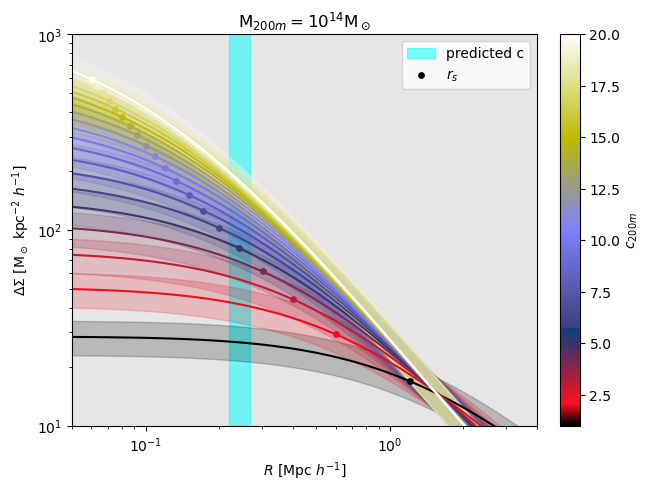

In [2]:

cpredicted = concentration.concentration(1E14, '200m',z= 0.5, model = 'diemer19')


fig, ax = plt.subplots(layout='constrained')
ax.set_facecolor((0.9,0.9,0.9)) 
log10M200 = 14
redshift=0.5
radii= np.logspace(-2,1,100)
cmin=1.0
cmax=20
norm = colors.Normalize(vmin=cmin, vmax=cmax)
R200 = xlensing.model.r_vir_m(redshift,10**log10M200)
maxgamma = np.sqrt(0.1/0.6) #metacal paper

minrs = 0.9*R200/cpredicted
maxrs = 1.1*R200/cpredicted
plt.fill_betweenx([0,2e3],[minrs,minrs],[maxrs,maxrs],color='cyan',alpha=.5,label='predicted c')
gNFW= np.vectorize(xlensing.sims.gNFW)
cmap = 'gist_stern'
for C200 in np.linspace(cmin,cmax,20):  
  RS = R200/C200
  X = radii


  Y =xlensing.model.NFW_shear(
      10**log10M200, 
      C200, 
      redshift, 
      1.0, 
      .0, 
      0.,
      X)['Signal']
  col = plt.get_cmap(cmap)(norm(C200)) 
  #plt.errorbar(radii,Y,0.1*Y,color=col)
  plt.fill_between(radii,Y-Y*.2,Y+Y*0.2,color=col,alpha=.2)
  plt.plot(radii,Y,color=col,alpha=1)
  if C200 == cmin:
    plt.scatter(RS,xlensing.model.NFW_shear(
      10**log10M200, 
      C200, 
      redshift, 
      1.0, 
      .0, 
      0.,
      np.array([RS]))['Signal'][0],color=col,s=15,label='$r_s$',zorder=3)
  else:
    #plt.axvline(RS,color=col)
    plt.scatter(RS,xlensing.model.NFW_shear(
      10**log10M200, 
      C200, 
      redshift, 
      1.0, 
      .0, 
      0.,
      np.array([RS]))['Signal'][0],color=col,s=15,zorder=3)

      
fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),
             ax=ax, orientation='vertical', label='$c_{200m}$')
plt.legend()
plt.xscale('log')
plt.yscale('log')
plt.xlabel('$R$ $[\\mathrm{Mpc}~h^{-1}]$')
plt.ylabel('$\\Delta \\Sigma$ $[\\mathrm{M}_\\odot ~ \\mathrm{kpc}^{-2} ~h^{-1}]$')
#plt.ylabel('$\\gamma$')
plt.ylim([1e1,1e3])
plt.xlim([5e-2,4])
modotstr = '$\\mathrm{M}_\\odot=$'
logmassstr = f'{log10M200}'
plt.title(f'$\\mathrm{{M}}_{{200m}}=10^{{{logmassstr}}} \\mathrm{{M}}_\\odot $')
plt.savefig('observability_deltasigma.png',bbox_inches='tight')

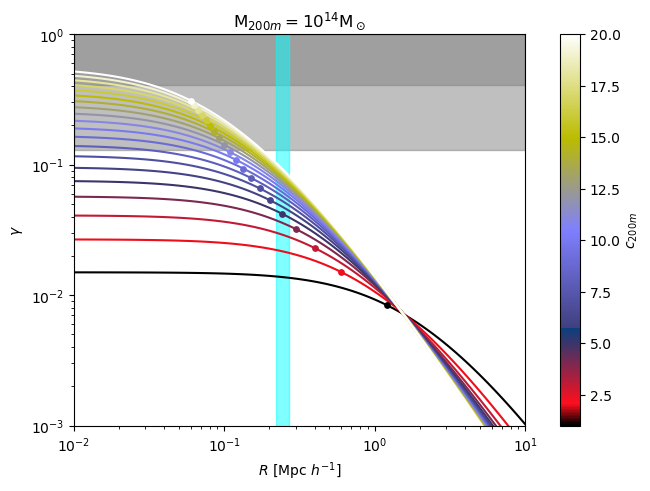

In [3]:
fig, ax = plt.subplots(layout='constrained')

maxgamma = np.sqrt(0.01/0.6) #metacal paper
plt.fill_between([1e-2,1e1],[maxgamma,maxgamma],[1,1],color='gray',alpha=.5)
maxgamma = np.sqrt(0.1/0.6) #metacal paper
plt.fill_between([1e-2,1e1],[maxgamma,maxgamma],[1,1],color='gray',alpha=.5)
minrs = 0.9*R200/cpredicted
maxrs = 1.1*R200/cpredicted
plt.fill_betweenx([0,1],[minrs,minrs],[maxrs,maxrs],color='cyan',alpha=.5)

for C200 in np.linspace(cmin,cmax,20):  
  RS = R200/C200
  X = radii/RS

  Y = xlensing.sims.NFW_tangential_shear(Mlens=10**log10M200, conc=C200, zlens=redshift, zsource=redshift+2, r=radii)

  col = plt.get_cmap(cmap)(norm(C200)) 
  plt.plot(radii,Y,color=col)

  if C200 == cmin:
    plt.scatter(RS,xlensing.sims.NFW_tangential_shear(Mlens=10**log10M200, conc=C200, zlens=redshift, zsource=redshift+2, 
                                                      r=np.array([RS]))[0],color=col,s=15,zorder=3)
  else:
    #plt.axvline(RS,color=col)
    plt.scatter(RS,xlensing.sims.NFW_tangential_shear(Mlens=10**log10M200, conc=C200, zlens=redshift, zsource=redshift+2, 
                                                      r=np.array([RS]))[0],color=col,s=15,zorder=3)
fig.colorbar(cm.ScalarMappable(norm=norm, cmap=cmap),
             ax=ax, orientation='vertical', label='$c_{200m}$')

plt.xscale('log')
plt.yscale('log')
plt.xlabel('$R$ $[\\mathrm{Mpc}~h^{-1}]$')
#plt.ylabel('$\\Delta \\Sigma$ $[\\mathrm{M}_\\odot ~ \\mathrm{kpc}^{-2} ~h^{-1}]$')
plt.ylabel('$\\gamma$')
plt.ylim([0.001,1.])
plt.xlim([1e-2,1e1])
modotstr = '$\\mathrm{M}_\\odot=$'
logmassstr = f'{log10M200}'
plt.title(f'$\\mathrm{{M}}_{{200m}}=10^{{{logmassstr}}} \\mathrm{{M}}_\\odot $')
plt.savefig('observability_gamma.png',bbox_inches='tight')